# STEP 0
### Sector definition and validation
**Topic:** Smart Glasses (Focus on hearing enhancement and audio technologies)

Define the boundaries of the sector by eliminating false positives (e.g., heavy VR headsets) and validate the semantic proximity of the extracted patents to Amplifon’s niche.

#### import the libraries

In [1]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sqlalchemy import and_, case, distinct, func, literal, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # import the needed tables for the extractions
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS206_PERSON,
    TLS207_PERS_APPLN,
    TLS224_APPLN_CPC,
    TLS230_APPLN_TECHN_FIELD,
    TLS901_TECHN_FIELD_IPC,
    TLS224_APPLN_CPC,
    TLS209_APPLN_IPC
)

# Initiate the client object
ENV = "PROD"
patstat = PatstatClient(ENV)
db = patstat.orm()  

## 1. Query construction
To isolate the smart glasses market, we selected relevant CPC/IPC codes along with specific keywords. To eliminate "noise" stemming from military-grade headsets or gaming consoles, we applied a **logical exclusion condition (NOT)** for keywords related to virtual reality and helmets.

In [2]:
SECTOR_NAME = "smart glasses"
CPC_CODES = ["G02B27/017"]
IPC_CODES = ["G02B27/01"]
KEYWORDS = ["bone conduction", "hearing aid", "directional microphone", "auditory", "wearable audio", "acoustic device"]
EXCLUDE_KEYWORDS = ["virtual reality", "vr headset", "head mounted display", "helmet"]
YEAR_MIN, YEAR_MAX = 2012, 2022 

In [3]:
def symbol_prefix_condition(symbol_column, codes):
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code + "%") for code in codes))

def keyword_condition(terms):
    title = func.lower(TLS202_APPLN_TITLE.appln_title)
    abstract = func.lower(TLS203_APPLN_ABSTR.appln_abstract)
    return or_(*(col.like(f"%{t.lower()}%") for t in terms for col in (title, abstract)))
    
def sector_family_ids():
    family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")
    
    # Identify the entire potential market (Inclusion)
    by_cpc = db.query(family_id).join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id).filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, CPC_CODES))
    by_ipc = db.query(family_id).join(TLS209_APPLN_IPC, TLS201_APPLN.appln_id == TLS209_APPLN_IPC.appln_id).filter(symbol_prefix_condition(TLS209_APPLN_IPC.ipc_class_symbol, IPC_CODES))
    by_keywords = db.query(family_id).outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id).outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id).filter(keyword_condition(KEYWORDS))
    
    base_ids = by_cpc.union(by_ipc).union(by_keywords)
    
    # Find VR headsets and helmets (Exclusion)
    to_exclude = db.query(family_id).outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id).outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id).filter(keyword_condition(EXCLUDE_KEYWORDS))
    
    # Subtract exclusion from the entire market
    return base_ids.except_(to_exclude)

sector_ids = sector_family_ids()


## 2. Extraction and sample creation (Hand-Labeling)
The required unit of analysis is the `docdb_family_id`. We extract the full texts and filter by the earliest priority year (`earliest_filing_year >= 2010`), calculated across the entire family. Finally, we export 100 random records for manual labeling in order to calculate the precision of the query.

In [4]:
from pathlib import Path
OUTPUT_DIR = Path("outputs/step0")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

extract_query = (
    db.query(
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.earliest_filing_year,
        TLS202_APPLN_TITLE.appln_title,
        TLS203_APPLN_ABSTR.appln_abstract,
        TLS201_APPLN.appln_auth
    )
    .join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
    .join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
    .filter(TLS201_APPLN.docdb_family_id.in_(sector_ids.subquery().select()))
    .filter(TLS203_APPLN_ABSTR.appln_abstract_lg == 'en')
)

df_raw = patstat.df(extract_query)
df_raw['family_year'] = df_raw.groupby('docdb_family_id')['earliest_filing_year'].transform('min')
df_families = df_raw[(df_raw['family_year'] >= YEAR_MIN) & (df_raw['family_year'] <= YEAR_MAX)].drop_duplicates(subset=['docdb_family_id']).copy()

# Export 100 sample
df_sample = df_families.sample(n=min(100, len(df_families)), random_state=42)
df_sample['is_relevant (1=Yes, 0=No)'] = ""

output_file = OUTPUT_DIR / "Hand_Labeling_SmartGlasses.xlsx"
df_sample[['docdb_family_id', 'family_year', 'appln_title', 'appln_abstract', 'is_relevant (1=Yes, 0=No)']].to_excel(output_file, index=False)

print(f"Extracted a total of {len(df_families)} patents. Excel file for validation saved to: {output_file}")

Extracted a total of 56882 patents. Excel file for validation saved to: outputs/step0/Hand_Labeling_SmartGlasses.xlsx


## Rationale for semantic filtering: The limitation of CPC codes
While the official CPC code G02B 27/017 accurately identifies "Head-mounted displays," it is extremely broad from a commercial and strategic perspective. Patent offices use this single classification to categorize vastly different devices, ranging from lightweight, everyday smart glasses (e.g., Ray-Ban Meta) to bulky, fully immersive Virtual Reality headsets designed for gaming (e.g., Meta Quest or PlayStation VR).
This broad technological categorization perfectly explains the high noise ratio (86% false positives) observed during our manual labeling phase. Standard database queries using CPC codes and generic keywords capture the entire market, indiscriminately mixing Amplifon's target technologies with unrelated VR gaming hardware.
To successfully isolate the acoustic and hearing-enhancement niche from the broader Head-Mounted Display market, traditional filtering is insufficient. Therefore, we implement an advanced Artificial Intelligence approach using SBERT. By calculating the semantic similarity between the full text of the patents and an ideal acoustic prompt, SBERT allows us to bypass the limitations of CPC codes and algorithmically extract only the highly relevant patents.

## 3. Semantic analysis and technology map (SBERT and UMAP)
To validate the actual presence of technologies relevant to the company's focus (Amplifon), we vectorize the dataset using SBERT and calculate the *cosine similarity* against an ideal prompt ("smart glasses with hearing enhancement"). The results are then projected into two dimensions using UMAP.

In [5]:
%pip install -q rank-bm25 sentence-transformers umap-learn

Note: you may need to restart the kernel to use updated packages.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/1778 [00:00<?, ?it/s]

Starting UMAP projection... This will take a few minutes on 53k records.


/opt/conda/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


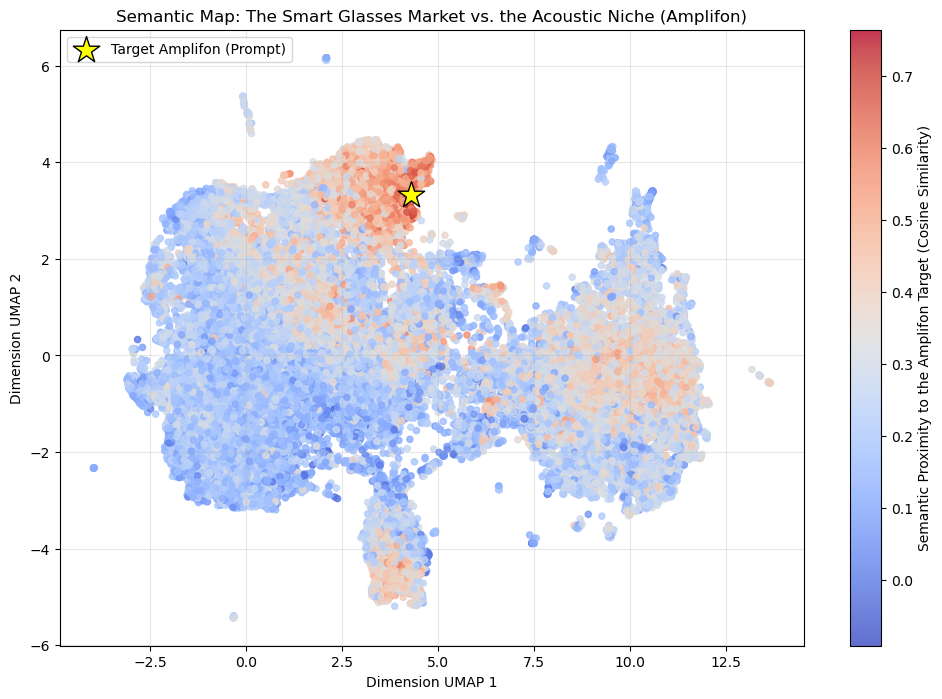


--- THE 5 PATENTS CLOSEST TO THE AMPLIFON NICHE (FULL DATASET) ---
Score: 0.76 | Title: SMART GLASSES FOR HEARING-IMPAIRED PERSON
Score: 0.75 | Title: SMART GLASSES TO ASSIST THOSE WHO ARE DEAF OR HARD OF HEARING
Score: 0.74 | Title: SMART EYEGLASSES FOR SPECIAL NEEDS CHILDREN AND ADULTS
Score: 0.74 | Title: Smart eyeglasses for special needs children and adults
Score: 0.74 | Title: Glasses that integrate an acoustic perception device (Machine-translation by Google Translate, not legally binding)


In [6]:
import re
import numpy as np
import umap
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt


df_plot = df_families.copy()
model = SentenceTransformer('all-MiniLM-L6-v2')

# 3. DEFINE THE TARGET (Amplifon)
prompt = "Smart glasses and wearable eyewear devices equipped with bone conduction transducers, acoustic audio delivery, microphones, and hearing aid capabilities for hearing impaired users or audio enhancement."

df_plot['full_text'] = df_plot['appln_title'].fillna('') + " - " + df_plot['appln_abstract'].fillna('')
patent_texts = df_plot['full_text'].tolist()
prompt_embedding = model.encode([prompt])
patent_embeddings = model.encode(patent_texts, show_progress_bar=True)

# CALCULATE COSINE SIMILARITY
similarities = cosine_similarity(prompt_embedding, patent_embeddings)[0]
df_plot['amplifon_similarity'] = similarities

# UMAP PROJECTION (Dimensionality Reduction)
print("Starting UMAP projection... This will take a few minutes on 53k records.")
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42)
all_embeddings = list(patent_embeddings) + list(prompt_embedding)
embeddings_2d = reducer.fit_transform(all_embeddings)

patent_2d = embeddings_2d[:-1]
prompt_2d = embeddings_2d[-1:]

# PLOT THE SEMANTIC MAP
plt.figure(figsize=(12, 8))
scatter = plt.scatter(patent_2d[:, 0], patent_2d[:, 1], c=similarities, s=20, alpha=0.8, cmap='coolwarm')
plt.colorbar(scatter, label='Semantic Proximity to the Amplifon Target (Cosine Similarity)')
plt.scatter(prompt_2d[:, 0], prompt_2d[:, 1], s=400, c='yellow', marker='*', edgecolor='black', label='Target Amplifon (Prompt)') 

plt.title('Semantic Map: The Smart Glasses Market vs. the Acoustic Niche (Amplifon)')
plt.xlabel('Dimension UMAP 1')
plt.ylabel('Dimension UMAP 2')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

# 8. EXTRACT THE ABSOLUTE TOP 5 PATENTS
print("\n--- THE 5 PATENTS CLOSEST TO THE AMPLIFON NICHE (FULL DATASET) ---")
df_top_amplifon = df_plot.sort_values('amplifon_similarity', ascending=False).head(5)
for idx, row in df_top_amplifon.iterrows():
    print(f"Score: {row['amplifon_similarity']:.2f} | Title: {row['appln_title']}")


### Comments on the results

1. Visual Confirmation of the Manual Labeling
The UMAP projection visually confirms the statistical distribution observed during the manual labeling phase, where 86% of the sample consisted of irrelevant patents (labeled as '0') and only 14% were in target (labeled as '1'). The massive blue cloud dominating the map represents this 86% of "noise"—patents related to generic smart glasses applications, such as visual AR displays and integrated cameras. Conversely, the highly concentrated red/orange region, where the target prompt (yellow star) is perfectly positioned, represents the 14% niche focused on acoustic technologies and bone conduction.   

2. Validation of the Semantic Filtering (SBERT)
This plot demonstrates that the initial extraction based solely on CPC codes (yielding over 53,000 documents) was too broad for Amplifon's specific strategic focus. Without the semantic filtering provided by the SBERT model, the target niche would have remained hidden within a vast "ocean" of purely visual and unrelated technologies. The algorithm successfully identified the acoustic concept, isolating the relevant niche while effectively discarding the peripheral, entirely blue clusters.   

3. Identification of a Well-Defined Technological Cluster
The fact that the high-scoring (red) patents are not randomly scattered across the map, but rather densely clustered around the target prompt, provides mathematical evidence that the acoustic niche possesses a distinct and homogeneous technical vocabulary. The SBERT model mapped this vocabulary with high precision, proving its reliability for this specific analysis.   

Conclusion:
Manual labeling highlighted a 86% false-positive rate when relying strictly on general CPC/IPC codes. The UMAP projection across the entire dataset confirms this proportion on a macroscopic scale, proving the absolute necessity of applying a semantic filter (SBERT) to successfully isolate the acoustic and hearing-enhancement cluster relevant to Amplifon.

In [7]:
import os

os.makedirs(OUTPUT_DIR, exist_ok=True)
file_path = "outputs/step0/step0_amplifon_full_dataset.csv"
df_plot.to_csv(file_path, index=False)

print(f"Completed exportation: File saved in: {file_path}")

Completed exportation: File saved in: outputs/step0/step0_amplifon_full_dataset.csv
